#load the latest snapshot from database

In [6]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch

con = sqlite3.connect("../data/market.db")
latest = pd.read_sql("SELECT MAX(snapshot_id) AS id FROM snapshots", con)["id"].iloc[0]
df_all = pd.read_sql(
    """
    SELECT v.*, b.tier
    FROM variants v JOIN brands b USING (brand)
    WHERE v.snapshot_id = ?
    """,
    con, params=(int(latest),),
)

# Tier = retail channel: prestige if sold at Sephora or department stores, mass otherwise
TIER_ORDER = ["mass", "prestige"]
TIER_COLORS = {"mass": "#9ecae1", "prestige": "#08519c"}
handles = [Patch(color=c, label=t) for t, c in TIER_COLORS.items()]

# Brands with any other tier label (TBD, dtc_only) are left out of tier comparisons
unassigned = sorted(df_all.loc[~df_all["tier"].isin(TIER_ORDER), "brand"].unique())
if unassigned:
    print("Left out of tier comparisons (fix their tier in stores.csv):", unassigned)
df = df_all[df_all["tier"].isin(TIER_ORDER)].copy()

Path("../charts").mkdir(exist_ok=True)
print(df.groupby("tier")["brand"].unique())
df.shape
df.head(10)

tier
mass                         [ColourPop, Frank Body, Morphe]
prestige    [Fenty Beauty, Glossier, Kylie Cosmetics, Rhode]
Name: brand, dtype: object


,snapshot_id,brand,product_id,variant_id,product_title,variant_title,product_type,category,sku,price,compare_at_price,on_sale,discount_pct,size_value,size_unit,size_source,unit_price,available,url,tier
0,1,ColourPop,7141916679,22676048583,Bae,Default Title,Super Shock Shadow,eyes,SSShadow-Bae,7.0,0.0,0,NaN,NaN,NaN,NaN,NaN,1,https://colourpop.com/products/bae-eyeshadow,mass
1,1,ColourPop,7141921351,22676069703,Bangin' Brunette Pencil,Default Title,Brow Pencil,eyes,BrowPencil-BangingBrunette,9.0,0.0,0,NaN,0.09,g,description,100.000,1,https://colourpop.com/products/bangin-brunette...,mass
2,1,ColourPop,7141962439,22676184647,Black N' Brown Pencil,Default Title,Brow Pencil,eyes,BrowPencil-BlackNBrown,9.0,0.0,0,NaN,0.09,g,description,100.000,1,https://colourpop.com/products/black-n-brown-p...,mass
3,1,ColourPop,7142083975,22676541319,DGAF,Default Title,Super Shock Shadow,eyes,SSShadow-DGAF,7.0,0.0,0,NaN,NaN,NaN,NaN,NaN,1,https://colourpop.com/products/dgaf,mass
4,1,ColourPop,7142098311,22676583943,Dope Taupe Pencil,Default Title,Brow Pencil,eyes,BrowPencil-DopeTaupe,9.0,0.0,0,NaN,0.09,g,description,100.000,1,https://colourpop.com/products/dope-taupe-pencil,mass
5,1,ColourPop,7142105543,22676602567,Drift,Default Title,Super Shock Shadow,eyes,SSShadow-Drift,7.0,0.0,0,NaN,NaN,NaN,NaN,NaN,1,https://colourpop.com/products/drift,mass
6,1,ColourPop,7142118151,22676637191,Empire,Default Title,Super Shock Shadow,eyes,SSShadow-Empire,7.0,0.0,0,NaN,NaN,NaN,NaN,NaN,0,https://colourpop.com/products/empire-green-ey...,mass
7,1,ColourPop,7142213063,22676916935,Hippo,Default Title,Super Shock Highlighter,lips,SSHighlighter-Hippo,9.0,0.0,0,NaN,4.20,g,description,2.143,1,https://colourpop.com/products/hippo,mass
8,1,ColourPop,7142225479,22676952327,I Heart This,Default Title,Super Shock Shadow,eyes,SSShadow-IHeartThis,7.0,0.0,0,NaN,NaN,NaN,NaN,NaN,0,https://colourpop.com/products/i-heart-this-sh...,mass
9,1,ColourPop,7142310151,22677227463,Lunch Money,Default Title,Super Shock Highlighter,face,SSHighlighter-LunchMoney,9.0,0.0,0,NaN,4.20,g,description,2.143,1,https://colourpop.com/products/lunch-money,mass


**within the same category, whats the price difference between prestige vs mass by finding median in each category**

In [3]:
ladder = (df.pivot_table(index="category", columns="tier", values="price", aggfunc="median")
            .reindex(columns=TIER_ORDER).round(2))
ladder["prestige_vs_mass"] = (ladder["prestige"] / ladder["mass"]).round(1)
ladder.sort_values("prestige_vs_mass", ascending=False)

tier,mass,prestige,prestige_vs_mass
category,,,
face,13.00,34.0,2.6
eyes,10.00,25.0,2.5
other,36.00,64.0,1.8
skincare,20.00,36.0,1.8
lips,16.00,24.0,1.5
body,31.00,30.0,1.0
tools,30.75,26.0,0.8
fragrance,NaN,71.8,NaN
hair,NaN,20.0,NaN


In [4]:
lips = df[df["category"] == "lips"]
lips_median = lips.groupby(["tier", "brand"])["unit_price"].median()
lips_median

tier      brand          
mass      ColourPop          2.143
          Frank Body         2.000
          Morphe             2.566
prestige  Fenty Beauty       4.464
          Glossier           4.000
          Kylie Cosmetics      NaN
          Rhode              2.000
Name: unit_price, dtype: float64

**Price per ml of product**

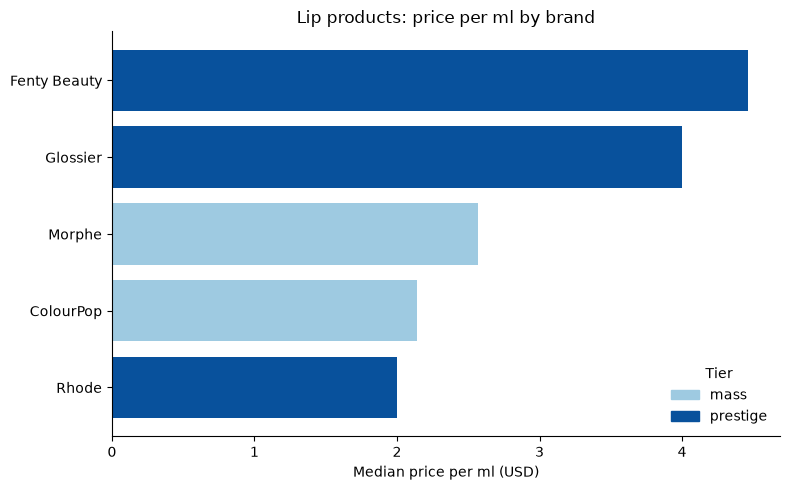

In [7]:
lips = df[(df["category"] == "lips")]
unit = (lips.groupby(["brand", "tier"])["unit_price"]
            .agg(median="median", n="count")
            .query("n >= 5")              # skip brands with too few sized lip items
            .reset_index()
            .sort_values("median"))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(unit["brand"], unit["median"], color=unit["tier"].map(TIER_COLORS))
ax.set_xlabel("Median price per ml (USD)")
ax.set_title("Lip products: price per ml by brand")
ax.legend(handles=handles, title="Tier", frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../charts/unit_price_lips.png", dpi=150)

,brand,tier,variants,pct_on_sale,median_discount,pct_out_of_stock
5,Morphe,mass,1663,95.2,25.0,10.1
4,Kylie Cosmetics,prestige,689,14.9,10.0,20.9
3,Glossier,prestige,333,8.7,30.8,2.1
1,Fenty Beauty,prestige,1133,7.1,50.0,16.4
0,ColourPop,mass,1116,1.4,30.0,4.0
2,Frank Body,mass,105,0.0,NaN,1.0
6,Rhode,prestige,187,0.0,NaN,42.2


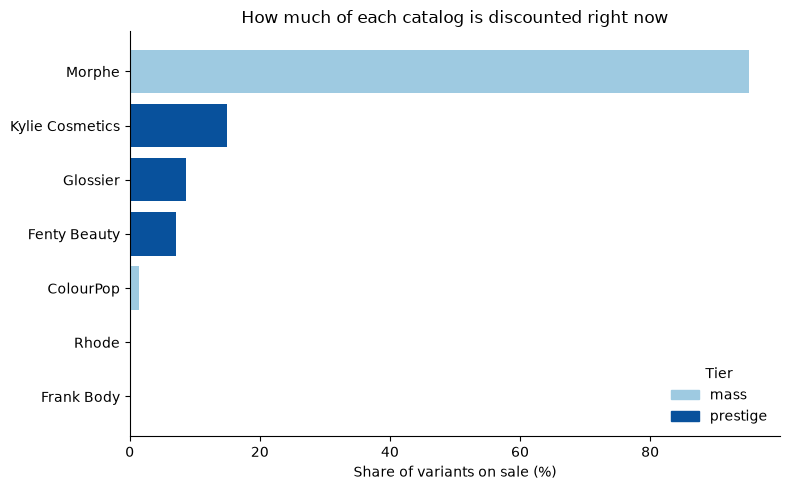

In [8]:
promo = (df.groupby(["brand", "tier"])
           .agg(variants=("variant_id", "count"),
                pct_on_sale=("on_sale", "mean"),
                median_discount=("discount_pct", "median"),
                pct_out_of_stock=("available", lambda s: 1 - s.mean()))
           .reset_index())
promo["pct_on_sale"] = (promo["pct_on_sale"] * 100).round(1)
promo["pct_out_of_stock"] = (promo["pct_out_of_stock"] * 100).round(1)
display(promo.sort_values("pct_on_sale", ascending=False))

promo_sorted = promo.sort_values("pct_on_sale")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(promo_sorted["brand"], promo_sorted["pct_on_sale"],
        color=promo_sorted["tier"].map(TIER_COLORS))
ax.set_xlabel("Share of variants on sale (%)")
ax.set_title("How much of each catalog is discounted right now")
ax.legend(handles=handles, title="Tier", frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../charts/on_sale.png", dpi=150)

# Conclusion

**Retail channel mostly predicts price per ml, but not always: Rhode, a prestige brand, is the cheapest lip brand per ml in this sample, and discounting is driven by one outlier (Morphe) rather than by tier.**

## Key findings

### 1. Prestige costs more than mass across categories
- **Finding:** the median prestige variant costs [X]× the median mass variant overall, with the widest gap in [category] ([X]×) and the narrowest in [category] ([X]×).
- **Evidence:** price ladder table above; n = [N] variants across [N] brands.

### 2. Price per ml for lip products: the tier order mostly holds, with one exception
- **Finding:** Fenty Beauty (~$4.45/ml) and Glossier (~$4.00/ml) charge the most per ml. Mass brands Morphe (~$2.57/ml) and ColourPop (~$2.14/ml) sit in the middle.
- **The exception:** Rhode, a prestige brand, is the cheapest at ~$2.00/ml, below both mass brands and less than half of Fenty's price per ml.
- **So what:** retail channel isn't a reliable proxy for value. Rhode competes on price per ml with mass brands while being sold in a prestige channel, which fits industry reports that mass and prestige pricing are converging.
- **Note:** Kylie Cosmetics and Frank Body aren't in this chart because they had fewer than 5 lip variants with a parsed size.

### 3. Discounting is brand-specific, not tier-specific
- **Finding:** Morphe has ~95% of its catalog on sale, far more than any other brand. Among the rest, prestige brands discount more often (Kylie Cosmetics ~15%, Glossier ~9%, Fenty Beauty ~7%) than mass brands ColourPop (~1%) and Frank Body (0%). Rhode has nothing on sale.
- **So what:** a near-sitewide "sale" usually signals a store-wide promotion or a habit of always showing a "was" price. For Morphe, the sticker price is effectively the discounted price, so its list prices overstate what shoppers pay.

## Limitations
- **One snapshot (2026-11-20):** taken a week before Black Friday, so discount levels are likely higher than usual and may change within days.
- **Sizes parsed from text:** [X]% of lip variants had a usable size. Brands with few sized products have less reliable medians.
- **Small sample:** 7 Shopify brands, [3] mass and [4] prestige. Results describe these brands, not the whole beauty market, and exclude retailers like Sephora and Ulta.
- **Tier is a binary label:** it comes from retail channel (sold at Sephora or not), so it can't capture brands positioned in between.
- **"Was" prices are set by each brand:** a sale flag means `compare_at_price` > `price`, which reflects the brand's own pricing choices, not independent verification.

## Next steps
- Rerun the scrape weekly to separate Black Friday effects from normal pricing, using the `snapshots` table.
- Add more brands per tier, especially mass brands, to make tier comparisons more robust.
- Investigate Morphe's pricing: is the discount permanent, or a temporary promotion?